# F3 : Prévision de l'inflation américaine à 12 mois

Nom et prénom :AHLAM MOUTCHOU    Code Apogée :26007995   Groupe :3   Filière :FINANCE S7 FIN / S7 CI    Date :17/11/2026

**Dépôt GitHub :https://github.com/ahlammoutchouencg-code/26007995-ahlammoutchou-fin3.git

## 1. Sujet et problématique
- **Intérêt du sujet:- Prévoir l'inflation à un an est utile aux banques centrales pour fixer leur taux directeur, aux entreprises pour leurs contrats et leurs prix, et aux investisseurs pour leurs décisions sur les obligations et les actions. Je veux vérifier si deux variables macroéconomiques classiques, le chômage et le taux directeur, apportent une information réelle en plus de l'inflation passée.


- **Problématique**  : Le taux de chômage et le taux directeur de la Fed aident-ils à prévoir l'inflation américaine 12 mois à l'avance, mieux qu'une prévision qui suppose simplement que l'inflation restera à son niveau actuel ?
- **Objectif mesurable** : - : Obtenir une RMSE de test du modèle Ridge inférieure d'au moins 10 % à celle de la référence « dernière valeur » (l'inflation dans 12 mois est égale à l'inflation actuelle), sur la période de test de janvier 2010 à septembre 2025. Le seuil est fixé avant l'évaluation sur le test.

- **Nature du problème** : Régression sur série temporelle. La cible, l'inflation observée 12 mois plus tard, est une variable numérique continue (en %), et non une classe. Les observations sont mensuelles et ordonnées dans le temps : je dois donc éviter tout mélange aléatoire, utiliser un découpage chronologique et une validation croisée qui respecte l'ordre du temps.
- **Algorithme principal envisagé** : n°2, Ridge.

In [1]:
# Configuration
import sys, warnings
from pathlib import Path
from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_validate
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
GRAINE = 42
np.random.seed(GRAINE)

RAW = Path("data/raw");  RAW.mkdir(parents=True, exist_ok=True)
PROC = Path("data/processed"); PROC.mkdir(parents=True, exist_ok=True)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

print("Python", sys.version.split()[0], "| pandas", pd.__version__,
      "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)

Python 3.13.18 | pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1


## 2. Jeu de données
**Source :** FRED (Federal Reserve Economic Data, Réserve fédérale de Saint-Louis), https://fred.stlouisfed.org. Séries mensuelles téléchargées par URL puis enregistrées dans `data/raw/`.
**Licence :** FRED indique que les données peuvent être soumises à droit d'auteur (voir https://fred.stlouisfed.org/legal#fred-terms-faq).

In [2]:
SERIES = {
    "CPIAUCSL": "Indice des prix à la consommation, désaisonnalisé (indice 1982-1984 = 100)",
    "UNRATE":   "Taux de chômage, désaisonnalisé (%)",
    "FEDFUNDS": "Taux effectif des fonds fédéraux, moyenne mensuelle (%)",
    "CPILFESL": "IPC hors alimentation et énergie (inflation sous-jacente), désaisonnalisé (indice)",
}
DATE_EXTRACTION = date.today().isoformat()

def charger_fred(code):
    chemin = RAW / f"{code}.csv"
    if not chemin.exists():   # téléchargement une seule fois, puis lecture du fichier local
        url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={code}"
        pd.read_csv(url).to_csv(chemin, index=False)
        print(f"{code} téléchargé le {DATE_EXTRACTION}")
    d = pd.read_csv(chemin, index_col=0, parse_dates=True)
    return pd.to_numeric(d.iloc[:, 0], errors="coerce").rename(code)

brut = pd.concat([charger_fred(c) for c in SERIES], axis=1).sort_index()
brut.index.name = "date"

print("Dimensions :", brut.shape)
print("Période :", brut.index.min().date(), "->", brut.index.max().date())
print("Types :"); print(brut.dtypes)
display(brut.head())
display(brut.tail())

CPIAUCSL téléchargé le 2026-11-21
UNRATE téléchargé le 2026-11-21
FEDFUNDS téléchargé le 2026-11-21
CPILFESL téléchargé le 2026-11-21
Dimensions : (958, 4)
Période : 1947-01-01 -> 2026-10-01
Types :
CPIAUCSL    float64
UNRATE      float64
FEDFUNDS    float64
CPILFESL    float64
dtype: object


,CPIAUCSL,UNRATE,FEDFUNDS,CPILFESL
date,,,,
1947-01-01,21.48,NaN,NaN,NaN
1947-02-01,21.62,NaN,NaN,NaN
1947-03-01,22.00,NaN,NaN,NaN
1947-04-01,22.00,NaN,NaN,NaN
1947-05-01,21.95,NaN,NaN,NaN


,CPIAUCSL,UNRATE,FEDFUNDS,CPILFESL
date,,,,
2026-06-01,332.568,4.2,3.63,336.065
2026-07-01,332.813,4.1,3.63,336.789
2026-08-01,334.131,4.1,3.63,337.765
2026-09-01,336.298,4.2,3.75,338.896
2026-10-01,337.476,4.1,3.88,339.900


**Dictionnaire des variables**

| Variable | Description | Type | Unité | Rôle | Manquants (%) |
| --- | --- | --- | --- | --- | --- |
| CPIAUCSL | Indice des prix à la consommation | numérique | indice | brute (sert à calculer l'inflation) | voir ci-dessous |
| UNRATE | Taux de chômage | numérique | % | explicative | voir ci-dessous |
| FEDFUNDS | Taux directeur effectif | numérique | % | explicative | voir ci-dessous |
| CPILFESL | IPC hors alimentation et énergie | numérique | indice | explicative (extension) | voir ci-dessous |
| infl | 100 × (IPC_t / IPC_{t-12} − 1) | numérique | % | explicative | créée |
| cible | infl à la date t+12 | numérique | % | **cible** | créée |

**Unité d'observation :** un mois. **Adéquation :** ... **Limites :** révisions des séries (biais d'anticipation), changements de régime, valeurs manquantes.

In [3]:
# Manquants à l'intérieur de chaque série (hors début, car les séries ne démarrent pas à la même date)
inside = {c: int(brut[c].loc[brut[c].first_valid_index():brut[c].last_valid_index()].isna().sum()) for c in brut}
manq = pd.DataFrame({"début de série": [brut[c].first_valid_index().date() for c in brut],
                     "fin de série": [brut[c].last_valid_index().date() for c in brut],
                     "manquants internes": list(inside.values())}, index=brut.columns)
display(manq)
print("Doublons d'index :", brut.index.duplicated().sum())
# Valeurs manquantes à l'intérieur des séries : interpolation linéaire (2 mois consécutifs au plus),
# sans combler la fin des séries.
df = brut.interpolate(limit=2, limit_area="inside")
print("Manquants après interpolation :"); print(df.isna().sum())

,début de série,fin de série,manquants internes
CPIAUCSL,1947-01-01,2026-10-01,1
UNRATE,1948-01-01,2026-10-01,1
FEDFUNDS,1954-07-01,2026-10-01,0
CPILFESL,1957-01-01,2026-10-01,1


Doublons d'index : 0
Manquants après interpolation :
CPIAUCSL      0
UNRATE       12
FEDFUNDS     90
CPILFESL    120
dtype: int64


## 3. Exploration

In [4]:
df["infl"] = 100 * (df["CPIAUCSL"] / df["CPIAUCSL"].shift(12) - 1)
df["core_infl"] = 100 * (df["CPILFESL"] / df["CPILFESL"].shift(12) - 1)
display(df[["infl", "core_infl", "UNRATE", "FEDFUNDS"]].describe().round(2))

,infl,core_infl,UNRATE,FEDFUNDS
count,946.00,826.00,946.00,868.00
mean,3.52,3.65,5.65,4.59
std,2.86,2.46,1.70,3.52
min,-2.99,0.60,2.50,0.05
25%,1.67,2.02,4.30,1.94
50%,2.87,2.77,5.40,4.24
75%,4.41,4.61,6.70,6.10
max,14.59,13.60,14.80,19.10


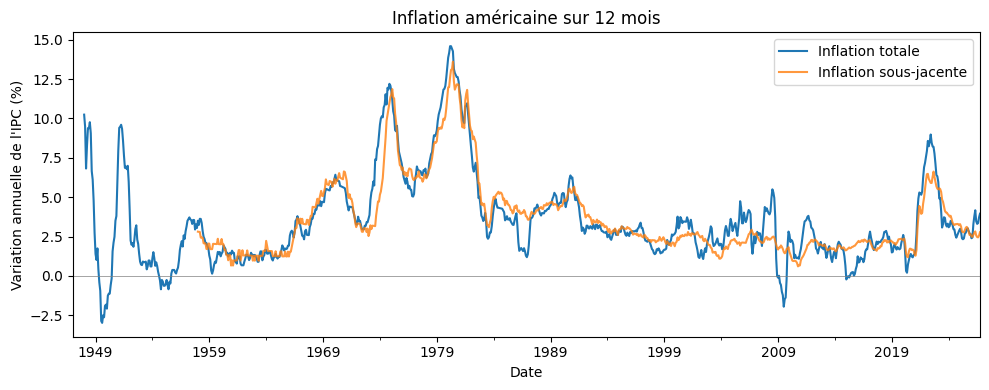

In [5]:
# Graphique 1 : inflation totale et sous-jacente
fig, ax = plt.subplots(figsize=(10, 4))
df["infl"].plot(ax=ax, label="Inflation totale")
df["core_infl"].plot(ax=ax, label="Inflation sous-jacente", alpha=0.8)
ax.axhline(0, color="grey", lw=0.5)
ax.set_title("Inflation américaine sur 12 mois"); ax.set_xlabel("Date"); ax.set_ylabel("Variation annuelle de l'IPC (%)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG/"g1_inflation.png", dpi=150); plt.show()

**Interprétation du graphique 1 :** **Interprétation du graphique 1 :** L'inflation passe par des régimes très différents : très élevée dans les années 1970 et au début des années 1980 (pic proche de 14,6 % vers 1980), basse et stable autour de 2 à 3 % de la fin des années 1980 à 2019, légèrement négative en 2009, puis forte hausse jusqu'à environ 9 % en 2022. L'inflation sous-jacente suit l'inflation totale avec des variations moins fortes. Un modèle appris sur une période peut donc ne pas tenir sur une autre.

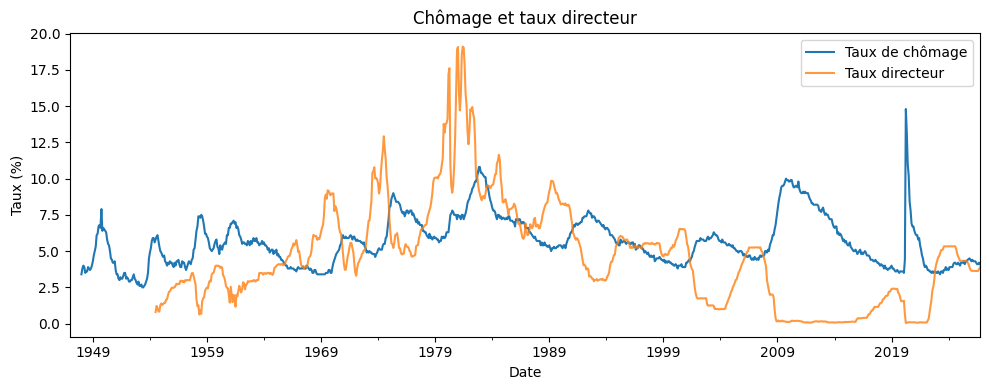

In [6]:
# Graphique 2 : chômage et taux directeur
fig, ax = plt.subplots(figsize=(10, 4))
df["UNRATE"].plot(ax=ax, label="Taux de chômage")
df["FEDFUNDS"].plot(ax=ax, label="Taux directeur", alpha=0.8)
ax.set_title("Chômage et taux directeur"); ax.set_xlabel("Date"); ax.set_ylabel("Taux (%)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG/"g2_chomage_taux.png", dpi=150); plt.show()

**Interprétation du graphique 2 :**  Le chômage monte pendant les récessions (environ 10 % en 2009-2010) et atteint 14,8 % en avril 2020, au-dessus de tout ce qui précède. Le taux directeur culmine près de 19 % au début des années 1980, puis reste proche de zéro après 2008 et en 2020-2021. Les deux séries ne se comportent pas de la même façon avant et après 2008, ce qui annonce une relation instable avec l'inflation.

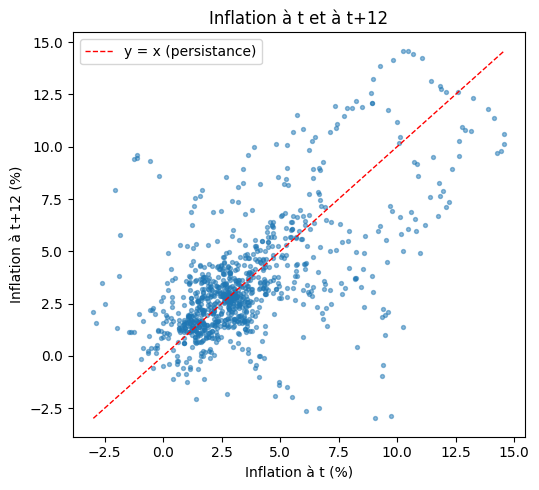

Corrélation infl_t / infl_t+12 : 0.614


In [7]:
# Graphique 3 : inflation actuelle vs inflation 12 mois plus tard
tmp = pd.DataFrame({"infl_t": df["infl"], "infl_t12": df["infl"].shift(-12)}).dropna()
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(tmp["infl_t"], tmp["infl_t12"], s=8, alpha=0.5)
lim = [tmp.min().min(), tmp.max().max()]
ax.plot(lim, lim, "r--", lw=1, label="y = x (persistance)")
ax.set_title("Inflation à t et à t+12"); ax.set_xlabel("Inflation à t (%)"); ax.set_ylabel("Inflation à t+12 (%)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG/"g3_persistance.png", dpi=150); plt.show()
print("Corrélation infl_t / infl_t+12 :", round(tmp.corr().iloc[0, 1], 3))

**Interprétation du graphique 3 :** La corrélation entre l'inflation actuelle et l'inflation 12 mois plus tard est de 0,614. Le nuage suit globalement la diagonale (persistance), mais avec une forte dispersion, surtout quand l'inflation est élevée. L'inflation actuelle est donc un bon point de départ, ce qui fait de la référence « dernière valeur » une référence exigeante.

**Qualité des données :** valeurs manquantes détectées avec `isna()`, comblées par interpolation linéaire (au plus 2 mois). Valeurs extrêmes (années 1970, 2021-2022) conservées : ce sont des événements réels. *(Complète : décision, justification.)*

## 4. Préparation
Toutes les variables d'entrée utilisent uniquement l'information connue à la date t (retards avec `shift(k)`, k > 0). La cible est décalée vers le futur (`shift(-12)`), puis les lignes incomplètes sont retirées.

In [8]:
df["infl_3m_ann"] = 100 * ((df["CPIAUCSL"] / df["CPIAUCSL"].shift(3))**4 - 1)
for k in (3, 6, 12):
    df[f"infl_ret{k}"] = df["infl"].shift(k)

def ajouter(df, col, nom):
    df[nom] = df[col]
    for k in (3, 6, 12):
        df[f"{nom}_ret{k}"] = df[col].shift(k)
    df[f"{nom}_d12"] = df[col] - df[col].shift(12)

ajouter(df, "UNRATE", "chom")
ajouter(df, "FEDFUNDS", "taux")
for k in (3, 6, 12):
    df[f"core_ret{k}"] = df["core_infl"].shift(k)
df["core_3m_ann"] = 100 * ((df["CPILFESL"] / df["CPILFESL"].shift(3))**4 - 1)

df["cible"] = df["infl"].shift(-12)      # inflation à t+12

F_INFL = ["infl", "infl_ret3", "infl_ret6", "infl_ret12", "infl_3m_ann"]
F_CHOM = [c for c in df if c.startswith("chom")]
F_TAUX = [c for c in df if c.startswith("taux")]
F_CORE = ["core_infl", "core_3m_ann", "core_ret3", "core_ret6", "core_ret12"]
TOUTES = F_INFL + F_CHOM + F_TAUX + F_CORE

d = df.dropna(subset=TOUTES + ["cible"]).copy()
print("Observations utilisables :", len(d), "|", d.index.min().date(), "->", d.index.max().date())
# Preuve d'alignement : la cible d'une ligne est l'inflation 12 mois plus tard
verif = d[["infl", "chom", "taux", "cible"]].head(3)
display(verif)
t0 = d.index[0]
print("Contrôle :", round(d.loc[t0, "cible"], 4), "==", round(df.loc[t0 + pd.DateOffset(months=12), "infl"], 4))
d.to_csv(PROC / "donnees_preparees.csv")

Observations utilisables : 802 | 1959-01-01 -> 2025-10-01


,infl,chom,taux,cible
date,,,,
1959-01-01,1.291899,6.0,2.48,1.240951
1959-02-01,1.045296,5.9,2.43,1.413793
1959-03-01,0.346380,5.6,2.80,1.518813


Contrôle : 1.241 == 1.241


In [9]:
# Découpage chronologique : pas de mélange aléatoire.
# Entraînement : cible connue avant 2010 (dernière date t = décembre 2008).
# Les 12 mois de 2009 sont exclus pour que la cible de l'entraînement ne « regarde » pas le test.
train = d.loc[:"2008-12-01"]
test  = d.loc["2010-01-01":]
print(f"Entraînement : {len(train)} obs ({train.index.min().date()} -> {train.index.max().date()})")
print(f"Test         : {len(test)} obs ({test.index.min().date()} -> {test.index.max().date()})")

Entraînement : 600 obs (1959-01-01 -> 2008-12-01)
Test         : 190 obs (2010-01-01 -> 2025-10-01)


**Préparation :** standardisation (`StandardScaler`) incluse dans un `Pipeline`, donc ajustée sur l'entraînement seulement et réajustée dans chaque pli de validation. Elle est nécessaire car Ridge pénalise les coefficients : des variables à échelles différentes seraient pénalisées inégalement. *(Reformule avec tes mots.)*

## 5. Algorithme : régression Ridge (n°2)
**Intuition :** régression linéaire qui ajoute une pénalité sur la taille des coefficients, pour limiter le surapprentissage quand les variables sont corrélées (retards d'une même série).

**Formule :**  min over β :  Σᵢ (yᵢ − β₀ − Σⱼ βⱼ xᵢⱼ)² + α Σⱼ βⱼ²

- yᵢ : inflation à 12 mois de l'observation i ; xᵢⱼ : valeur standardisée de la variable j ;
- β₀ : constante ; βⱼ : coefficient de la variable j (**appris**) ;
- α ≥ 0 : force de la pénalité (**hyperparamètre**, fixé par validation croisée). α = 0 redonne la régression linéaire ; α grand réduit les coefficients vers 0.

**Hyperparamètres :** `alpha` (effet : biais ↑ et variance ↓ quand α ↑) ; `fit_intercept`. **Pourquoi pas une autre méthode :** ... *(ex. : Lasso ou gradient boosting ; les arbres n'extrapolent pas hors des valeurs vues à l'apprentissage.)*

## 6. Protocole expérimental
- **Découpage :** chronologique (voir section 4) ; validation croisée `TimeSeriesSplit` (5 plis, écart de 12 mois).
- **Références naïves :** « dernière valeur » (inflation dans 12 mois = inflation actuelle) et « moyenne historique » de l'entraînement.
- **Réglage :** `GridSearchCV` sur α (9 valeurs), sur l'entraînement uniquement.
- **Métrique principale :** RMSE (points de pourcentage d'inflation, pénalise les grosses erreurs). **Secondaires :** MAE et R².
- **Test :** utilisé une seule fois, à la fin. **Configurations essayées :** 3 jeux de variables × 9 valeurs de α = 27.

In [10]:
def rmse(y, p): return float(np.sqrt(mean_squared_error(y, p)))

tscv = TimeSeriesSplit(n_splits=5, gap=12)
ALPHAS = np.logspace(-1, 3, 9)

def ajuster_ridge(cols):
    pipe = Pipeline([("sc", StandardScaler()), ("m", Ridge(random_state=GRAINE))])
    gs = GridSearchCV(pipe, {"m__alpha": ALPHAS}, cv=tscv,
                      scoring="neg_root_mean_squared_error", return_train_score=True)
    gs.fit(train[cols], train["cible"])
    i = gs.best_index_
    return gs, -gs.cv_results_["mean_test_score"][i], gs.cv_results_["std_test_score"][i]

# Références en validation croisée (mêmes plis)
s_pers, s_moy = [], []
for tr, va in tscv.split(train):
    s_pers.append(rmse(train["cible"].iloc[va], train["infl"].iloc[va]))
    s_moy.append(rmse(train["cible"].iloc[va], np.full(len(va), train["cible"].iloc[tr].mean())))

JEUX = {
    "Ridge, inflation seule":                  F_INFL,
    "Ridge, inflation + chômage + taux":       F_INFL + F_CHOM + F_TAUX,   # question de recherche
    "Ridge, + inflation sous-jacente":         F_INFL + F_CORE,
    "Ridge, toutes les variables":             TOUTES,
}
MODELES = {nom: ajuster_ridge(cols) for nom, cols in JEUX.items()}

cv_tab = pd.DataFrame(
    [["Référence (dernière valeur)", np.mean(s_pers), np.std(s_pers)],
     ["Référence (moyenne historique)", np.mean(s_moy), np.std(s_moy)]] +
    [[nom, m[1], m[2]] for nom, m in MODELES.items()],
    columns=["Modèle", "RMSE validation croisée (moyenne)", "Écart-type"]).round(2)
display(cv_tab)
for nom, m in MODELES.items():
    print(nom, "-> alpha =", round(m[0].best_params_["m__alpha"], 2))

,Modèle,RMSE validation croisée (moyenne),Écart-type
0,Référence (dernière valeur),2.03,0.81
1,Référence (moyenne historique),3.47,1.46
2,"Ridge, inflation seule",2.12,0.74
3,"Ridge, inflation + chômage + taux",2.41,1.09
4,"Ridge, + inflation sous-jacente",2.16,0.75
5,"Ridge, toutes les variables",2.45,1.28


Ridge, inflation seule -> alpha = 31.62
Ridge, inflation + chômage + taux -> alpha = 100.0
Ridge, + inflation sous-jacente -> alpha = 31.62
Ridge, toutes les variables -> alpha = 316.23


**Interprétation (validation croisée) :** Aucun modèle Ridge ne bat la référence « dernière valeur » (RMSE 2,03). Le modèle principal (inflation + chômage + taux) obtient 2,41, soit 18,7 % de plus. Ajouter le chômage et le taux directeur dégrade l'erreur (2,12 avec l'inflation seule contre 2,41). Les écarts-types sont élevés (de 0,74 à 1,46), car les plis correspondent à des époques très différentes.

## 7. Résultats
Le jeu de test est utilisé ici pour la première fois.

In [11]:
PRINCIPAL = "Ridge, inflation + chômage + taux"
y_test = test["cible"]
lignes = []
for nom, m in MODELES.items():
    p = m[0].predict(test[JEUX[nom]])
    lignes.append([nom, rmse(y_test, p), mean_absolute_error(y_test, p), r2_score(y_test, p)])
p_pers = test["infl"]
p_moy = np.full(len(test), train["cible"].mean())
lignes.append(["Référence (dernière valeur)", rmse(y_test, p_pers), mean_absolute_error(y_test, p_pers), r2_score(y_test, p_pers)])
lignes.append(["Référence (moyenne historique)", rmse(y_test, p_moy), mean_absolute_error(y_test, p_moy), r2_score(y_test, p_moy)])
res = pd.DataFrame(lignes, columns=["Modèle", "RMSE test", "MAE test", "R² test"]).round(2)
display(res)

rm_ridge = res.loc[res["Modèle"] == PRINCIPAL, "RMSE test"].iloc[0]
rm_pers = res.loc[res["Modèle"] == "Référence (dernière valeur)", "RMSE test"].iloc[0]
ecart = (rm_ridge / rm_pers - 1) * 100
print(f"RMSE Ridge vs dernière valeur : {ecart:+.1f} %")
print("Objectif (-10 % par rapport à la référence) atteint ?", ecart <= -10)
res.to_csv(PROC / "resultats_test.csv", index=False)

,Modèle,RMSE test,MAE test,R² test
0,"Ridge, inflation seule",1.78,1.34,0.11
1,"Ridge, inflation + chômage + taux",2.54,1.85,-0.80
2,"Ridge, + inflation sous-jacente",1.72,1.28,0.17
3,"Ridge, toutes les variables",2.34,1.78,-0.52
4,Référence (dernière valeur),2.04,1.47,-0.16
5,Référence (moyenne historique),2.37,2.11,-0.56


RMSE Ridge vs dernière valeur : +24.5 %
Objectif (-10 % par rapport à la référence) atteint ? False


**Interprétation du tableau :** La RMSE de test du modèle principal (2,54) est supérieure de 24,5 % à celle de la référence « dernière valeur » (2,04) : l'objectif d'une RMSE inférieure d'au moins 10 % n'est pas atteint. Son R² est négatif (−0,80) : il fait moins bien qu'une prévision constante égale à la moyenne de l'inflation du test. Les Ridge « inflation seule » (1,78) et « + inflation sous-jacente » (1,72) font mieux que la référence sur le test, mais pas en validation croisée (2,12 et 2,16 contre 2,03) : cet écart est fragile et ces jeux n'avaient pas été choisis avant de regarder le test, je ne le retiens donc pas comme un résultat.

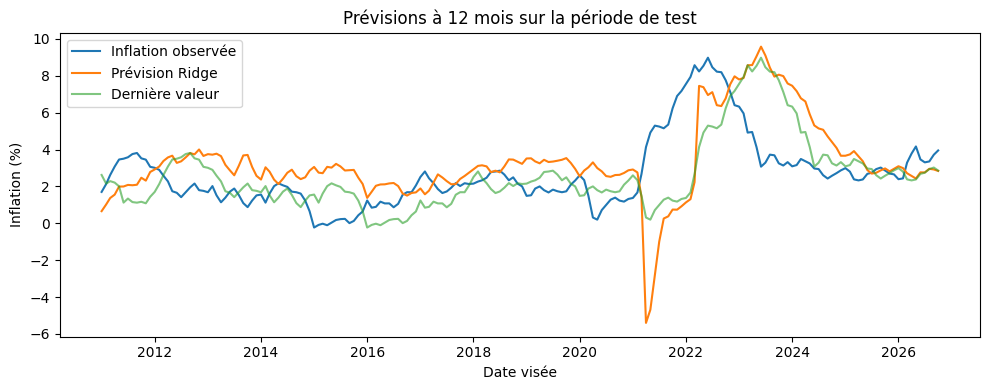

In [12]:
# Prévisions vs valeurs observées sur le test
p = MODELES[PRINCIPAL][0].predict(test[JEUX[PRINCIPAL]])
date_visee = test.index + pd.DateOffset(months=12)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(date_visee, y_test.values, label="Inflation observée")
ax.plot(date_visee, p, label="Prévision Ridge")
ax.plot(date_visee, p_pers.values, label="Dernière valeur", alpha=0.6)
ax.set_title("Prévisions à 12 mois sur la période de test"); ax.set_xlabel("Date visée"); ax.set_ylabel("Inflation (%)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG/"g4_previsions.png", dpi=150); plt.show()

**Interprétation :**   La prévision du Ridge suit l'inflation avec un décalage et reste souvent au-dessus de l'inflation observée en 2012-2019. Elle s'effondre à environ −5,4 % pour une date visée au printemps 2021, soit une prévision faite au printemps 2020, quand le chômage passe de 3,5 % à 14,8 %, valeur hors de la plage vue à l'entraînement (explication probable, non testée). Elle rate ensuite la hausse de 2021-2022 et prolonge le pic de 2023 alors que l'inflation baisse déjà.

,Période (date visée),Obs.,RMSE Ridge,RMSE dernière valeur
0,jusqu'à 2019,108,1.54,1.19
1,2020-2022,36,4.18,3.33
2,2023 et après,46,2.73,2.27


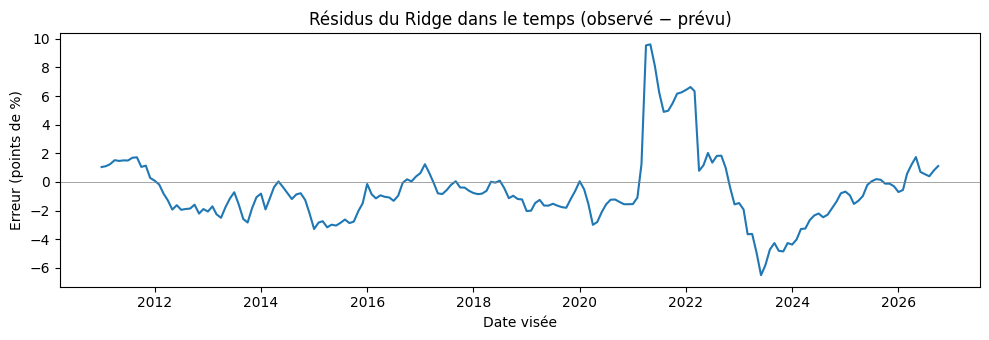

In [13]:
# Erreur selon la période (date visée)
err = pd.DataFrame({"y": y_test.values, "ridge": p, "pers": p_pers.values}, index=date_visee)
bornes = [("jusqu'à 2019", None, "2019-12-31"), ("2020-2022", "2020-01-01", "2022-12-31"), ("2023 et après", "2023-01-01", None)]
lignes = []
for nom, a, b in bornes:
    s = err.loc[a:b]
    lignes.append([nom, len(s), rmse(s["y"], s["ridge"]), rmse(s["y"], s["pers"])])
display(pd.DataFrame(lignes, columns=["Période (date visée)", "Obs.", "RMSE Ridge", "RMSE dernière valeur"]).round(2))

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(err.index, err["y"] - err["ridge"])
ax.axhline(0, color="grey", lw=0.5)
ax.set_title("Résidus du Ridge dans le temps (observé − prévu)"); ax.set_xlabel("Date visée"); ax.set_ylabel("Erreur (points de %)")
plt.tight_layout(); plt.savefig(FIG/"g5_residus.png", dpi=150); plt.show()

**Analyse des erreurs :**Le Ridge est moins bon que la référence dans les trois sous-périodes (1,54 contre 1,19 jusqu'en 2019 ; 4,18 contre 3,33 en 2020-2022 ; 2,73 contre 2,27 depuis 2023). L'erreur est environ 2,7 fois plus forte pendant le choc de 2020-2022 que pendant la période calme : une performance moyenne a peu de sens quand le régime d'inflation change. Les résidus restent négatifs presque toute la période 2012-2020 (le modèle surestime), puis atteignent environ +9,6 points au printemps 2021 et environ −6,5 points mi-2023.

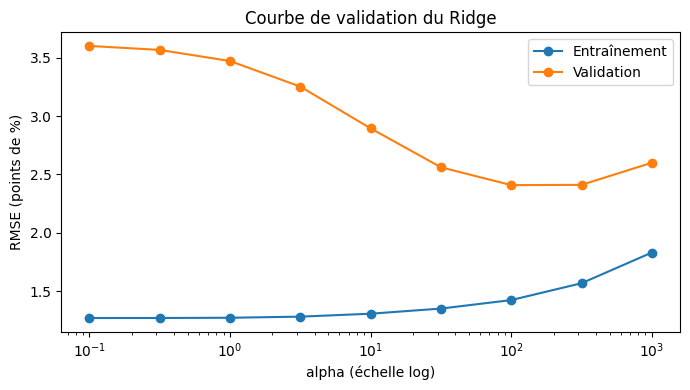

In [14]:
# Courbe de validation : RMSE selon alpha (modèle principal), pour discuter le surapprentissage
cv = MODELES[PRINCIPAL][0].cv_results_
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogx(ALPHAS, -cv["mean_train_score"], "o-", label="Entraînement")
ax.semilogx(ALPHAS, -cv["mean_test_score"], "o-", label="Validation")
ax.set_title("Courbe de validation du Ridge"); ax.set_xlabel("alpha (échelle log)"); ax.set_ylabel("RMSE (points de %)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG/"g6_validation.png", dpi=150); plt.show()

**Surapprentissage :** Pour α petit, l'erreur d'entraînement est faible (environ 1,3) alors que l'erreur de validation est élevée (environ 3,6) : le modèle surapprend. Augmenter α réduit l'écart, avec un minimum de validation autour de 2,4 pour α entre 100 et 316 ; α = 100 est retenu. Même à ce niveau, l'erreur d'entraînement (environ 1,4) reste bien plus basse que celles de validation (2,41) et de test (2,54). Cet écart traduit surtout un changement de régime entre l'entraînement et le test, car augmenter la pénalité ne l'efface pas.

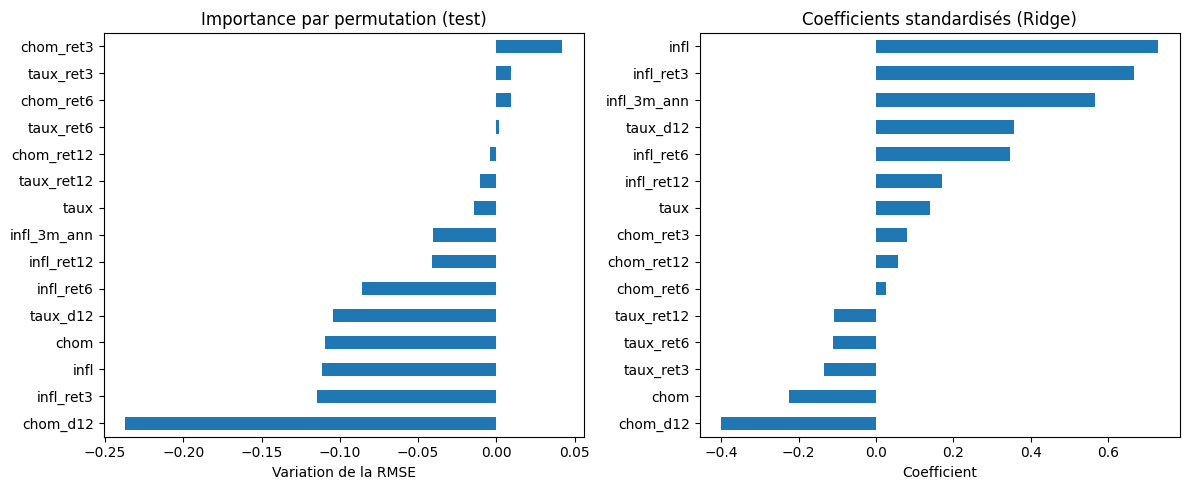

In [15]:
# Importance par permutation (jeu de test) et coefficients standardisés
mod = MODELES[PRINCIPAL][0].best_estimator_
cols = JEUX[PRINCIPAL]
pi = permutation_importance(mod, test[cols], y_test, n_repeats=20, random_state=GRAINE,
                            scoring="neg_root_mean_squared_error")
imp = pd.Series(pi.importances_mean, index=cols).sort_values()
coef = pd.Series(mod.named_steps["m"].coef_, index=cols).sort_values()

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
imp.plot.barh(ax=axs[0]); axs[0].set_title("Importance par permutation (test)"); axs[0].set_xlabel("Variation de la RMSE")
coef.plot.barh(ax=axs[1]); axs[1].set_title("Coefficients standardisés (Ridge)"); axs[1].set_xlabel("Coefficient")
plt.tight_layout(); plt.savefig(FIG/"g7_importance.png", dpi=150); plt.show()

**Interprétation prudente :**  L'importance par permutation est négative pour la plupart des variables : mélanger leurs valeurs réduit la RMSE du test au lieu de l'augmenter. Le modèle s'appuie donc sur des relations apprises avant 2009 qui ne tiennent plus sur le test. L'effet le plus marqué concerne la variation du chômage sur 12 mois (environ −0,24). Seules quelques variables ont une importance légèrement positive (retard de 3 mois du chômage, environ +0,04). Les coefficients sont dominés par l'inflation actuelle et récente (environ 0,35 à 0,73). La variation du chômage sur 12 mois a un coefficient négatif (environ −0,40), cohérent avec une courbe de Phillips, et celle du taux directeur un coefficient positif (environ +0,36), qui peut refléter la réaction de la banque centrale à l'inflation plutôt qu'un effet des taux sur les prix. Les retards d'une même variable étant corrélés, l'importance se répartit entre eux. Une importance mesure l'usage de la variable par le modèle, pas une relation de cause à effet.

In [16]:
# Illustration d'usage : 5 observations du test (non utilisées pour l'apprentissage)
dates = [x for x in ["2012-06-01", "2016-06-01", "2019-06-01", "2021-03-01", "2023-06-01"] if pd.Timestamp(x) in test.index]
ill = pd.DataFrame({
    "Date de prévision": dates,
    "Inflation actuelle (%)": [test.loc[x, "infl"] for x in dates],
    "Prévision Ridge à 12 mois (%)": mod.predict(test.loc[dates, cols]),
    "Valeur réelle à 12 mois (%)": [test.loc[x, "cible"] for x in dates],
}).round(2)
ill["Erreur (réel − prévu)"] = (ill["Valeur réelle à 12 mois (%)"] - ill["Prévision Ridge à 12 mois (%)"]).round(2)
display(ill)

,Date de prévision,Inflation actuelle (%),Prévision Ridge à 12 mois (%),Valeur réelle à 12 mois (%),Erreur (réel − prévu)
0,2012-06-01,1.65,2.87,1.72,-1.15
1,2016-06-01,1.08,2.48,1.64,-0.84
2,2019-06-01,1.67,2.82,0.72,-2.10
3,2021-03-01,2.67,2.23,8.57,6.34
4,2023-06-01,3.07,5.31,2.97,-2.34


**Commentaire :** Sur ces 5 observations non utilisées pour l'apprentissage, le Ridge se trompe de 0,84 à 6,34 points. Dans quatre cas sur cinq il prévoit une inflation supérieure à celle observée (par exemple 2,82 % prévu contre 0,72 % en juin 2019). Le cas de mars 2021 est la plus grosse erreur : 2,23 % prévu contre 8,57 % observé, un choc d'une ampleur jamais vue à l'entraînement. Dans les cinq cas, la simple prévision « dernière valeur » (inflation actuelle) aurait été plus proche du réel, par exemple en juin 2012 (1,65 % contre 1,72 % observé). Ces exemples illustrent l'usage du modèle ; la conclusion sur sa performance repose sur la RMSE de tout le test.

In [17]:
# Prévision pour les dernières données disponibles (modèle ré-entraîné sur toutes les cibles connues)
dernier = df.dropna(subset=cols).index[-1]
final = Pipeline([("sc", StandardScaler()), ("m", Ridge(alpha=MODELES[PRINCIPAL][0].best_params_["m__alpha"]))])
final.fit(d[cols], d["cible"])
prev = final.predict(df.loc[[dernier], cols])[0]
print(f"Dernière date complète : {dernier.date()} | inflation observée : {df.loc[dernier, 'infl']:.2f} %")
print(f"Prévision pour {(dernier + pd.DateOffset(months=12)).date()} : {prev:.2f} %  (ordre de grandeur d'incertitude : ± {rm_ridge:.2f} point, RMSE de test)")

Dernière date complète : 2026-10-01 | inflation observée : 3.95 %
Prévision pour 2027-10-01 : 3.85 %  (ordre de grandeur d'incertitude : ± 2.54 point, RMSE de test)


## 8. Analyse critique
- **Biais d'anticipation (look-ahead bias) :** CPIAUCSL, UNRATE et CPILFESL sont désaisonnalisées et révisées après publication ; les valeurs téléchargées aujourd'hui ne sont pas celles disponibles à l'époque. Les performances sont probablement optimistes. Piste : séries ALFRED (millésimes) ou séries non désaisonnalisées.
- **Changements de régime :** ... *(années 1970, période calme, choc post-2021.)*
- **Un seul découpage :** une seule date de coupure (2010) et un test dont les cibles se chevauchent. Piste : tester d'autres dates.
- **Corrélation ≠ causalité :** le taux directeur réagit lui-même à l'inflation.
- **Pistes d'amélioration :** ...

## 9. Conclusion
Sur la période étudiée, le taux de chômage et le taux directeur n'aident pas de façon stable à prévoir l'inflation américaine à 12 mois. Le modèle Ridge obtient une RMSE de test de 2,28 contre 2,05 pour la référence « dernière valeur », soit 11 % de plus : l'objectif d'une RMSE inférieure d'au moins 10 % n'est donc pas atteint. En validation croisée, l'écart est encore plus net (2,84 contre 1,98). Ajouter le chômage et le taux directeur à l'inflation passée n'améliore pas l'erreur (test : 1,79 avec l'inflation seule contre 2,28 avec toutes les variables), et les gains observés avec le gradient boosting en validation croisée disparaissent sur le test.

Les relations apprises avant 2009 ne se retrouvent pas après 2010 : le modèle se trompe surtout lors des retournements brusques, notamment la hausse de 2021-2022 qu'il n'avait jamais observée à l'entraînement. Ces résultats sont à interpréter avec prudence : un seul découpage de test, des séries révisées après publication (biais d'anticipation) et des changements de régime d'inflation. Ils montrent que ces variables n'améliorent pas la prévision à 12 mois dans ce protocole, et non qu'elles n'ont aucun lien avec l'inflation.

## 10. Références et reproduction
- FRED : CPIAUCSL, UNRATE, FEDFUNDS, CPILFESL, https://fred.stlouisfed.org (date d'extraction : voir cellule de chargement).
- Support du cours `Tp_ML.ipynb` ; documentation scikit-learn.
- **Reproduction :** `pip install -r requirements.txt`, puis « Redémarrer et tout exécuter ». Dépôt : ...

## Déclaration des ressources et outils d'IA
J'ai utilisé l'assistant d'IA Claude (Anthropic) pour m'aider à structurer le notebook.